Produces Fig. 1(c) of the paper.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ---------------------------------------------------------
# 1. Experiment Settings
# ---------------------------------------------------------
alpha = 1.0
tau = 2.0
eta_a = 0.8
eta_f = 0.8
lambda_ = 0.01
ghost_batch_size = 500

results = {"n": [], "raw": [], "spike": [], "dev_tilde": [], "remainder": []}


def run_scaling_sim(n):
    k = int(alpha * n)
    steps = int(tau * n)
    lr_a = eta_a / k
    lr_f = eta_f / k

    rng = np.random.default_rng(42)
    xi = rng.normal(0, 1, n)
    xi /= np.linalg.norm(xi)
    F = rng.normal(0, 1 / np.sqrt(n), (k, n))
    a = rng.normal(0, 1, k)

    F_perp = F @ (np.eye(n) - np.outer(xi, xi))
    G_t = F_perp @ F_perp.T
    C_tilde = F_perp @ F_perp.T
    C_spike = np.zeros((k, k))

    def teacher_func(z):
        return np.tanh(z)

    def sigma(x):
        return np.maximum(x, 0)

    def sigma_prime(x):
        return (x > 0).astype(float)

    for t in tqdm(range(steps)):
        # Forward
        z0 = rng.normal()
        g_train = rng.normal(0, 1, n)
        g_train -= np.dot(g_train, xi) * xi
        x_train = z0 * xi + g_train
        h = F @ x_train
        e = (np.dot(a, sigma(h)) / k) - teacher_func(z0)
        v_t = e * a * sigma_prime(h)

        # Ghost Batch for mu_t
        g_ghost = rng.normal(0, 1, (ghost_batch_size, n))
        g_ghost -= np.outer(g_ghost @ xi, xi)
        x_ghost = np.outer(np.ones(ghost_batch_size), z0 * xi) + g_ghost
        h_ghost = x_ghost @ F.T
        e_ghost = ((sigma(h_ghost) @ a) / k) - teacher_func(z0)
        mu_t = np.mean(e_ghost[:, None] * a[None, :] * sigma_prime(h_ghost), axis=0)

        # Components
        v_tilde_t = v_t - mu_t

        # Accumulate
        scale = ((n-1)/k) * ((eta_f) ** 2) / k 
        C_tilde += scale * np.outer(v_tilde_t, v_tilde_t)
        C_spike += scale * np.outer(mu_t, mu_t)

        # Update
        a -= lr_a * (e * sigma(h) + lambda_ * a)
        F -= lr_f * np.outer(v_t, x_train)

        F_perp = F @ (np.eye(n) - np.outer(xi, xi))
        G_t = F_perp @ F_perp.T

    R_matrix = G_t - C_tilde - C_spike

    return G_t, C_spike, C_tilde, R_matrix

n = 1000


G_t_list, C_spike_list, C_tilde_list, R_matrix_list = run_scaling_sim(n)

100%|██████████| 2000/2000 [02:10<00:00, 15.34it/s]


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import scienceplots
import numpy as np

mpl.rcParams.update(mpl.rcParamsDefault)

plt.style.use(["science", "bright"])
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times"],
        "font.size": 15.2,
        "axes.labelsize": 17.4,
        "figure.dpi": "600",
    }
)

In [3]:
def marchpast(l, g):
    "Marchenko-Pastur distribution"
    # Adapted from https://bnikolic.co.uk/blog/python/2019/11/28/marchenko-pastur.html

    def m0(a):
        "Element wise maximum of (a,0)"
        return np.maximum(a, np.zeros_like(a))

    gplus = (1 + g**0.5) ** 2
    gminus = (1 - g**0.5) ** 2
    return np.sqrt(m0(gplus - l) * m0(l - gminus)) / (2 * np.pi * g * l + 1e-8)

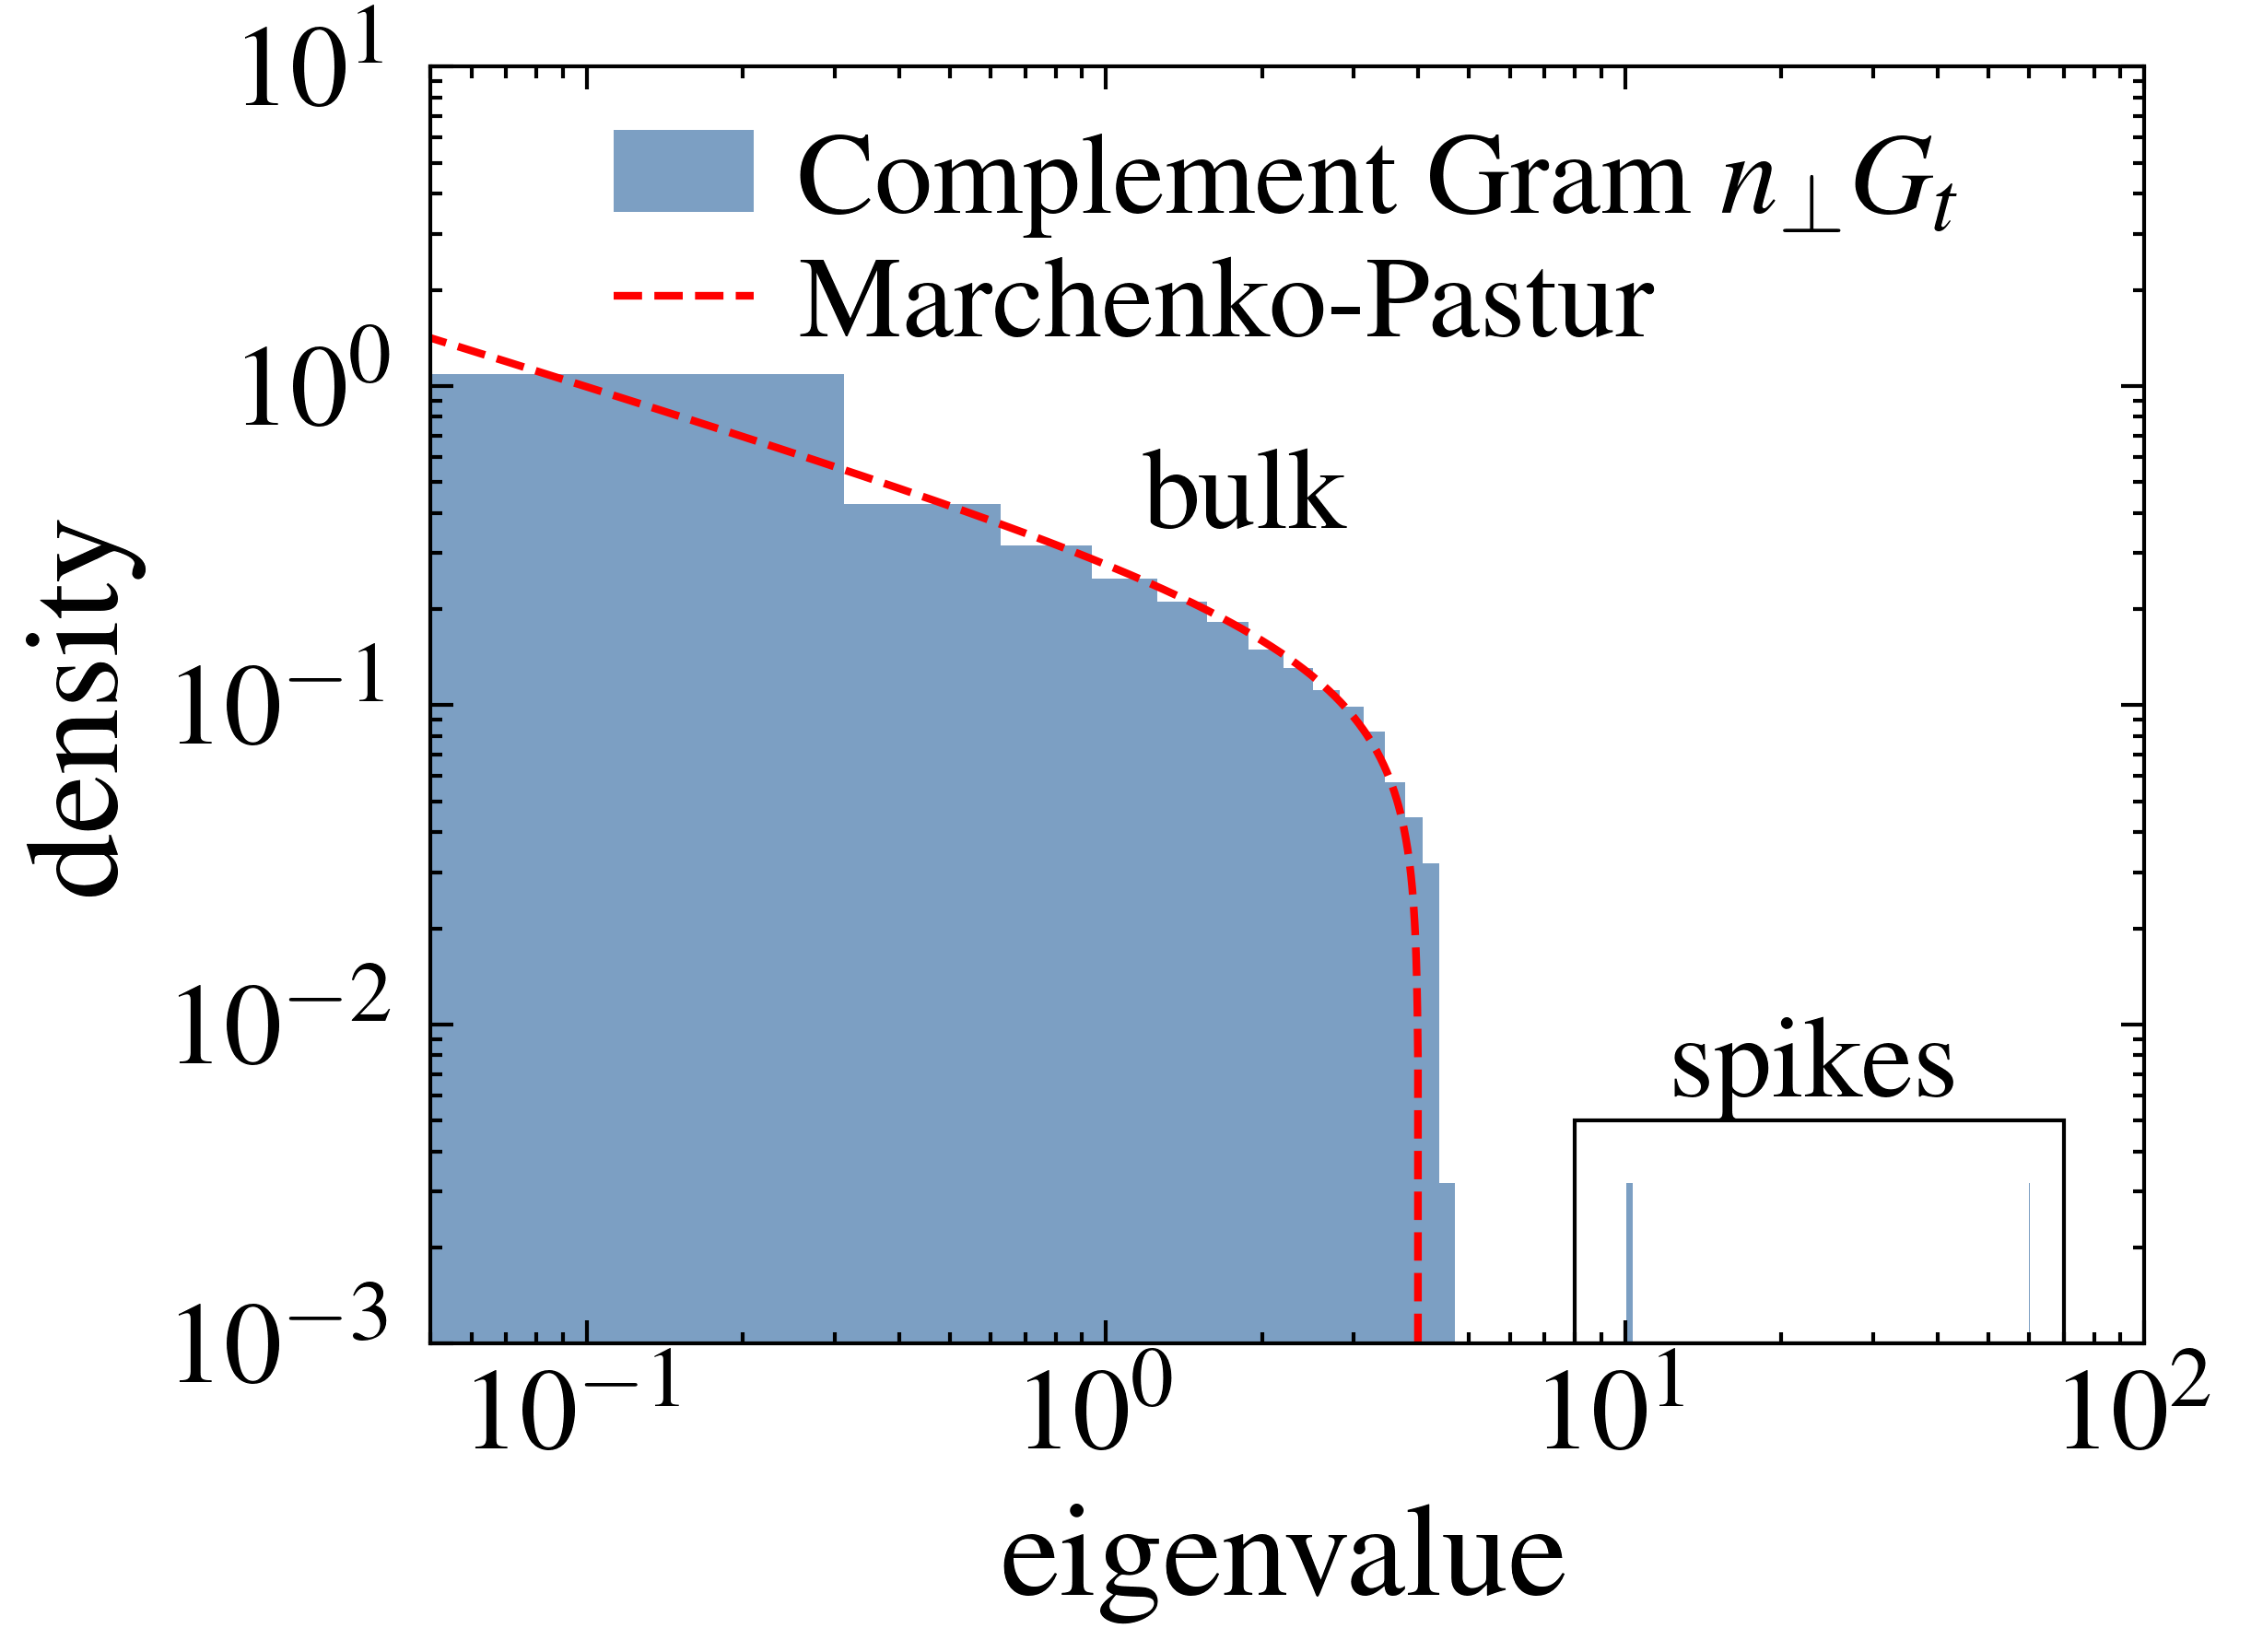

In [4]:
# Calculate eigenvalues of G_t
from matplotlib.patches import Rectangle


G_t_eig = np.linalg.eigvals(G_t_list)
# C_approx_eig = np.linalg.eigvals(np.mean(C_spike_list + C_tilde_list, axis=0))

x = np.linspace(0, 1e2, 10000)

# plot eigenvalue histogram
plt.figure(figsize=(4, 3))


# plot marchenko-pastur
plt.hist(G_t_eig, bins="auto", density=True, label=r"Complement Gram $n_\perp G_t$", alpha=0.7)
plt.plot(
    x,
    marchpast(x, alpha),
    label="Marchenko-Pastur",
    color="red",
    linestyle="dashed",
)
# plt.hist(C_tilde_eig, bins=500, density=True, label=r"n $\Tilde{C}(t)$", alpha=0.3)
plt.legend(
    loc="lower left",
    bbox_to_anchor=(0.1, 0.76),
    handlelength=1.2,
    handletextpad=0.4,
    labelspacing=0.15,
    borderpad=0.1,
    borderaxespad=0.0,
)

x0, x1 = 8, 70
y0, y1 = 1e-3, 5e-3
rect = Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, linewidth=0.5)
plt.gca().add_patch(rect)

plt.text((x0 * x1) ** 0.5, y1, "spikes", va="bottom", ha="center")

plt.text(1.85, 0.3, "bulk", va="bottom", ha="center")

plt.xlabel('eigenvalue')
plt.ylabel('density')
plt.ylim(0.001, 1e1)
plt.yscale('log')
plt.xscale('log')
plt.xlim(5e-2, 1e2)
plt.show()